### *Algoritmos Genéticos y Optimización Heurística - UTN-FRT*

# **Trabajo Práctico N°5**
### Tema: Aplicaciones de AG
### Objetivo: Aplicar heurísticas a problemas reales

***Integrantes***

*   Breslauer, León - 56340
*   Perez, Francisco - 56355



## Ejercicio 1

Utilice el AG Simple para resolver el problema del viajante o TSP (Travelling Salesman Problem):
* Se tienen **N** ciudades por las cuales el viajante debe pasar.
* El viajante pasa sólo una vez por cada ciudad.
* Inicia en una ciudad, hace su recorrido y vuelve a la ciudad de inicio.
* El objetivo es encontrar el camino más corto que el viajante debe recorrer para pasar por todas las ciudades.

El caso particular que usted debe resolver consiste de 14 ciudades, cuyas coordenadas son las siguientes (tomar la primera como punto de partida):

Ciudades para el problema de TSP


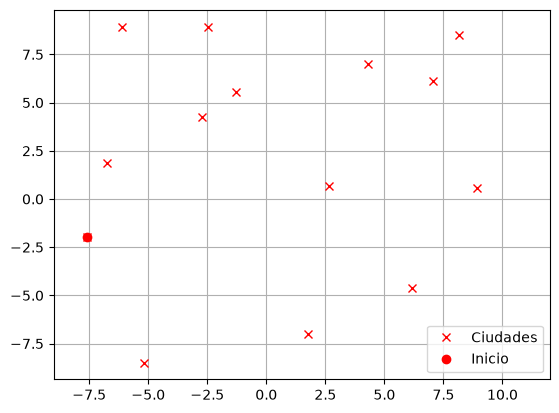

In [226]:
coordenadas = [
  [-7.5984,-1.9725],
  [-6.7323, 1.8807],
  [-2.7165, 4.2661],
  [-1.2992, 5.5505],
  [-6.1024, 8.9450],
  [-2.4803, 8.9450],
  [ 4.2913, 7.0183],
  [ 7.0472, 6.1009],
  [ 8.1496, 8.4862],
  [ 8.9370, 0.5963],
  [ 2.6378, 0.6881],
  [ 6.1811,-4.6330],
  [ 1.7717,-7.0183],
  [-5.1575,-8.4862]
]

x = [c[0] for c in coordenadas]
y = [c[1] for c in coordenadas]
import matplotlib.pyplot as plt
plt.plot(x, y, 'xr', label='Ciudades');
plt.plot(x[0], y[0], 'or', label='Inicio');
plt.legend()
plt.grid()
plt.xlim([-9,12])
print("Ciudades para el problema de TSP")

El algoritmo requiere conocer las distancias entre las ciudades para poder calcular la distancia total recorrida. Para ello se propone la siguiente funcion para calcular la distancia entre una ciudad *i* y *j*:

In [227]:
import math
def distancia(coord_i, coord_j):
  #distancia Euclidea
  return math.sqrt((coord_i[0]-coord_j[0])**2 + (coord_i[1]-coord_j[1])**2)

#ejemplo
ciudad_i = 1
ciudad_j = 5
d = distancia(coordenadas[ciudad_i], coordenadas[ciudad_j])
print("Distancia entre ciudad %d y %d; %f"%(ciudad_i, ciudad_j, d))

Distancia entre ciudad 1 y 5; 8.245231


Se pide:
1. Determinar una codificación adecuada (forma de representar las soluciones  para el problema).
2. Definir las restricciones para los valores en la solución (determinar la matriz de *Bounds*).
3. En base a la codificación elegida, definir una función *Fitness* que permita encontrar buenas soluciones en base al objetivo del problema.
4. Determinar una arquitectura de algoritmos genéticos adecuada para resolver el problema:
  * Definir que tipo de algoritmo genético utilizar.
  * Elegir los operadores genéticos a utilizar.
5. Ajustar los parámetros adecuadamentes usando los criterios utilizados en los prácticos anteriores. La cantidad de generaciones y tamaño de la población pueden variar al tomar diferentes cantidades de ciudades.

In [228]:
# @title
# Operadores adicionales

def sel_tournament(population, fitness, k=2):
    candidates = random.sample(range(len(population)), k)
    winner = min(candidates, key=lambda i: fitness[i])
    return population[winner]

def mut_swap(p, Bounds, n=1):
    m = p.copy()
    #genero permutacion al azar para elegir coordenadas distintas al azar
    r = list(range(len(m)-1))  #r = list(range(len(m)))
    random.shuffle(r)
    #indices de coordenadas origen
    o = r[:n]
    #indices de coordenadas destino
    d = r[n:2*n]
    #asigno nuevos valores a las coordenadas del mutado
    for i in range(len(o)):
        m[o[i]] = p[d[i]]
        m[d[i]] = p[o[i]]
    return m

def mut_adjoin_swap(p, Bounds, n=1):
    #copio el padre
    m = p.copy()
    #genero permutacion al azar para elegir coordenadas distintas al azar
    r = list(range(len(m)-1))  #r = list(range(len(m)))
    random.shuffle(r)
    #indices de coordenadas origen
    o = r[:n]
    #indices de coordenadas destino
    d = [(x + 1) for x in o]  #d = [(x + 1) % len(m) for x in o]
    #asigno nuevos valores a las coordenadas del mutado
    for i in range(len(o)):
        m[o[i]] = p[d[i]]
        m[d[i]] = p[o[i]]
    return m

def mut_inversion(p, Bounds):
    #copio el padre
    m = p.copy()
    #genero permutacion al azar para elegir dos puntos de corte distintos
    r = list(range(len(m)))
    random.shuffle(r)
    #indices de coordenadas origen
    #o = [x % len(m) for x in range(r[0], r[1] + (len(m) if r[1] < r[0] else 0))]
    o = [x for x in range(min(r[:2]), max(r[:2]))]
    #asigno nuevos valores a las coordenadas del mutado
    for i in range(len(o)):
        m[o[i]] = p[o[-i-1]]
    return m

def mut_shift_left(p, Bounds):
    #copio el padre
    m = p.copy()
    #genero permutacion al azar para elegir dos puntos de corte distintos
    r = list(range(len(m)))
    random.shuffle(r)
    #indices de coordenadas origen
    #o = [x % len(m) for x in range(r[0], r[1] + (len(m) if r[1] < r[0] else 0))]
    o = [x for x in range(min(r[:2]), max(r[:2]))]
    #indices de coordenadas destino
    d = [x + 1 for x in o]  #d = [(x + 1) % len(m) for x in o]
    d[-1] = o[0]
    #asigno nuevos valores a las coordenadas del mutado
    for i in range(len(o)):
        m[o[i]] = p[d[i]]
    return m

def mut_shift_right(p, Bounds):
    #copio el padre
    m = p.copy()
    #genero permutacion al azar para elegir dos puntos de corte distintos
    r = list(range(len(m)))
    random.shuffle(r)
    #indices de coordenadas origen
    #o = [x % len(m) for x in range(r[0], r[1] + (len(m) if r[1] < r[0] else 0))]
    o = [x for x in range(min(r[:2]), max(r[:2]))]
    #indices de coordenadas destino
    d = [x - 1 for x in o]  #d = [(x - 1) % len(m) for x in o]
    d[0] = o[-1]
    #asigno nuevos valores a las coordenadas del mutado
    for i in range(len(o)):
        m[o[i]] = p[d[i]]
    return m

def xov_partial_map(p1, p2):
    c1 = p1.copy()
    c2 = p2.copy()
    n = len(c1);
    #genero permutacion al azar para elegir dos puntos de corte distintos
    r = list(range(n))
    random.shuffle(r)
    #creo la mascara
    mask = [0]*n
    for i in range(min(r[:2]), max(r[:2])):
        mask[i] = 1
    #tacho valores que estan en p1 y p2
    m1 = [1]*n
    m2 = [1]*n
    for i in range(n):
        if not mask[i]:
            for j in range(n):
                if p1[i] == p2[j]:
                    m1[j] = 0
                if p2[i] == p1[j]:
                    m2[j] = 0
    j = k = 0
    #pongo calores no tachados en c1 y c2
    for i in range(n):
        if mask[i]:
            while m1[j] == 0:
                j += 1
            while m2[k] == 0:
                k += 1
            c1[i] = p2[j]
            c2[i] = p1[k]
            j += 1
            k += 1
    return c1, c2

def xov_order_based(p1, p2):
    c1 = p1.copy()
    c2 = p2.copy()
    n = len(c1)
    #crear mascara al azar
    mask = [random.randint(0,1) for i in range(n)]
    #tacho valores que estan en p1 y p2
    m1 = [1]*n
    m2 = [1]*n
    for i in range(n):
        if not mask[i]:
            for j in range(n):
                if p1[i] == p2[j]:
                    m1[j] = 0
                if p2[i] == p1[j]:
                    m2[j] = 0
    j = k = 0
    #pongo calores no tachados en c1 y c2
    for i in range(n):
        if mask[i]:
            while m1[j] == 0:
                j += 1
            while m2[k] == 0:
                k += 1
            c1[i] = p2[j]
            c2[i] = p1[k]
            j += 1
            k += 1
    return c1, c2

Siguiendo el criterio de los prácticos anteriores, se mantienen fijos el tamaño de la población (100 individuos), la probabilidad de cruzamiento (0.9), la de mutación (0.2) y el elitismo (1 individuo). El único parámetro que se ajusta es la *cantidad de generaciones*, que se aumenta cuando crece la cantidad de ciudades, ya que el espacio de búsqueda del TSP crece como (n−1)!/2 y el algoritmo necesita más iteraciones para converger.

Para n = 14 ciudades se usan 50 generaciones. Para validar el ajuste se corrieron 50 ejecuciones con semillas distintas y se comparó el mejor recorrido contra la distancia óptima exacta, calculada con programación dinámica (Held-Karp): 70.692.

In [229]:
# @title
def validate_params(initial_pop, quantity_generations, prob_xover, prob_mut):
  # Valida los parametros del AG. Lanza ValueError con un mensaje claro si algo esta mal.
  if not initial_pop:
    raise ValueError("La poblacion inicial no puede estar vacia")
  n = len(initial_pop[0])
  for ind in initial_pop:
    if sorted(ind) != list(range(n)):
      raise ValueError("Cada individuo debe ser una permutacion de 0..n-1 sin repetidos")
  if not isinstance(quantity_generations, int) or quantity_generations < 1:
    raise ValueError("quantity_generations debe ser un entero >= 1")
  if not (0 <= prob_xover <= 1):
    raise ValueError("prob_xover debe estar entre 0 y 1")
  if not (0 <= prob_mut <= 1):
    raise ValueError("prob_mut debe estar entre 0 y 1")
  return True

def tsp_ag(initial_pop, quantity_generations=50, prob_xover=0.9, prob_mut=0.2, trace_best = [], trace_avg = []):
  validate_params(initial_pop, quantity_generations, prob_xover, prob_mut)

  # Copio la poblacion inicial
  population = initial_pop.copy()

  # Fitness de la poblacion inicial
  fitness = [fitness_tsp(ind) for ind in population]
  best = min(population, key=fitness_tsp)

  for generation in range(quantity_generations):
      new_population = [best.copy()]  # elitismo
      while len(new_population) < len(population):
          parent1 = sel_tournament(population, fitness)
          parent2 = sel_tournament(population, fitness)

          # Crossover con probabilidad prob_xover; si no, los hijos son copias de los padres
          # Xover & Mutuación Probabilistíca
          if random.random() < prob_xover:
              child1, child2 = xov_partial_map(parent1, parent2)
          else:
              child1, child2 = parent1.copy(), parent2.copy()

          # Mutacion con probabilidad prob_mut, aplicada a cada hijo
          if random.random() < prob_mut:
              child1 = mut_inversion(child1, None)
          if random.random() < prob_mut:
              child2 = mut_inversion(child2, None)

          # Agrego los dos hijos (el segundo solo si todavia hay lugar)
          new_population.append(child1)
          if len(new_population) < len(population):
              new_population.append(child2)

      population = new_population
      fitness = [fitness_tsp(ind) for ind in population]
      best = min(population, key=fitness_tsp)
      trace_best.append(min(fitness))
      trace_avg.append(sum(fitness)/len(fitness))
  # Solo rota la ruta para que empiece en la ciudad 0 (no cambia el AG)
  start = best.index(0)
  best = best[start:] + best[:start]
  return best, fitness_tsp(best), trace_best, trace_avg


In [230]:
def fitness_tsp(X):
    return sum(distancia(coordenadas[X[i]], coordenadas[X[(i + 1) % len(X)]]) for i in range(len(X)))

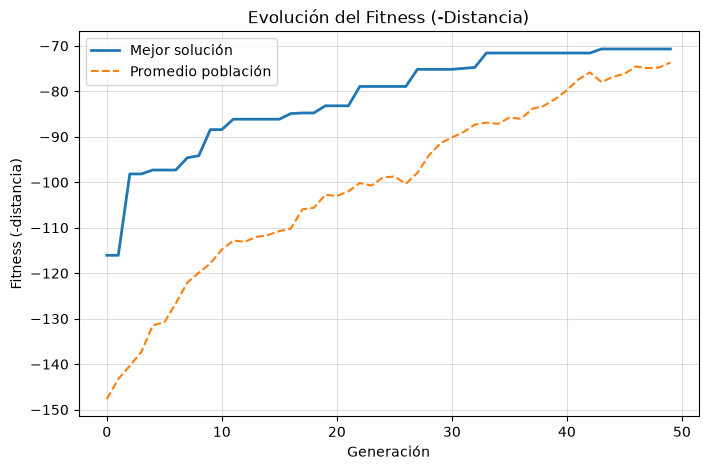

Best route: [0, 1, 4, 5, 3, 2, 10, 6, 8, 7, 9, 11, 12, 13]
Distance: 70.6920076856193


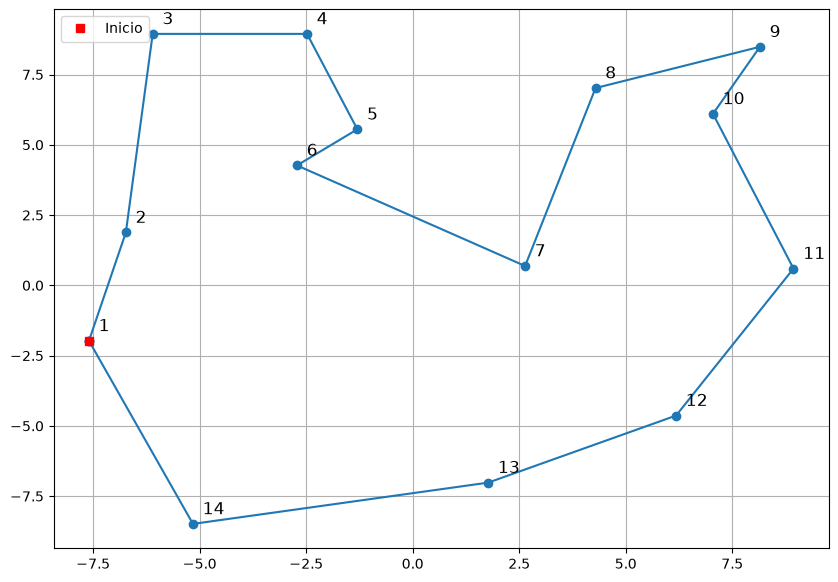

In [231]:
# @title
# Pruebo el AG
import random

# Inicializo una población de 100 individuos
initial_pop = [random.sample(range(14), 14) for _ in range(100)]
trace_best = []
trace_avg = []
best, distance, trace_best, trace_avg = tsp_ag(initial_pop, quantity_generations=50,
                        trace_best=trace_best, trace_avg=trace_avg)

# --- TROUBLESHOOTING ---
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot([-d for d in trace_best], label='Mejor solución', color='tab:blue', linewidth=2)
ax1.plot([-d for d in trace_avg], label='Promedio población', color='tab:orange', linestyle='--')
ax1.set_title('Evolución del Fitness (-Distancia)')
ax1.set_xlabel('Generación')
ax1.set_ylabel('Fitness (-distancia)')
ax1.grid(True, alpha=0.4)
ax1.legend()
plt.show()

print("Best route:", best)
print("Distance:", distance)

route = best + [best[0]]
x = [coordenadas[i][0] for i in route]
y = [coordenadas[i][1] for i in route]

plt.figure(figsize=(10, 7))
plt.plot(x, y, "-o")
plt.plot(x[0], y[0], "rs", label="Inicio")

for step, city in enumerate(best, start=1):
    plt.annotate(
        str(step),
        xy=coordenadas[city],
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=12
    )

plt.legend()
plt.grid()
plt.show()



Los valores del gráfico se presentan con signo negativo porque se grafica el fitness como el opuesto de la distancia total del recorrido (fitness = -distancia). De este modo, la curva crece a medida que el algoritmo mejora, lo que resulta más intuitivo de interpretar. Esta transformación no altera el problema de optimización, ya que minimizar la distancia equivale a maximizar su opuesto: min(d) = -max(-d). Se adopta únicamente para facilitar la visualización de la evolución.

In [232]:
# Esto es una forma por ejemplo de compararlo, pero según lo charlado en la clase de hoy 26/11; si bien esto es una forma
# que se puede utilizar, no es la ideal, debido a que, si ya sé "técnicamente" cuanto da el problema, entonces no voy por un AG para resolverlo.
import statistics
# Distancia optima: calculada con programacion dinamica exacta (Held-Karp) sobre las 14 ciudades.
# Antes este valor se tomo de una consulta a una IA; ahora esta verificado por calculo propio.
DISTANCIA_OPTIMA = 70.69200768561929

resultados = []
for seed in range(50):
    random.seed(seed)
    initial_pop = [[0] + random.sample(range(1, 14), 13) for _ in range(100)]
    best, distance = tsp_ag(initial_pop, quantity_generations=50)
    resultados.append(distance)

exitos = sum(1 for r in resultados if abs(r - DISTANCIA_OPTIMA) < 1e-6)
print("Mejor distancia:", min(resultados))
print("Media: %.3f  Desvio: %.3f  Peor: %.3f" % (statistics.mean(resultados), statistics.stdev(resultados), max(resultados)))
print("Corridas que llegan al optimo: %d/50" % exitos)
print("Distancia optima (Held-Karp):", DISTANCIA_OPTIMA)


ValueError: too many values to unpack (expected 2, got 4)

# Ej1 Variante de AG con Arquitectura de Mutuación & Xover Probabilístico netamente:

## 1. Codificación

Se utiliza una codificación de **permutación** de longitud fija \(N = 14\).

Cada individuo representa una ruta del viajante como una lista que contiene las 14 ciudades, sin repeticiones:

$
X = (x_0, x_1, \dots , x_{13})
$

donde cada $(x_i \in \{0, 1, \dots, 13\}$ representa una ciudad y todas las ciudades aparecen exactamente una vez.

La ruta se interpreta como un ciclo cerrado: el viajante recorre las ciudades en el orden indicado y vuelve desde la última ciudad hacia la primera.

**Restricciones:**

- Cada individuo debe ser una permutación de las ciudades $0$ a $13$.
- No se permiten ciudades repetidas.
- La primera ciudad puede ser cualquiera; al final, la mejor ruta se rota para que comience en la ciudad $0$, sin modificar la distancia total.

La población inicial se genera aleatoriamente mediante `random.sample(range(14), 14)`, lo que garantiza que cada individuo sea una permutación válida

## 2. Función de Evaluación

El objetivo del TSP es minimizar la distancia total recorrida por el viajante.

La función de evaluación calcula la suma de las distancias euclídeas entre ciudades consecutivas, incluyendo el retorno desde la última ciudad a la primera:

$
Fitness(X) = \sum_{i=0}^{N-1} d(x_i, x_{(i+1) \bmod N})
$

donde $d(x_i, x_j)$ es la distancia euclídea entre las ciudades $x_i$ y $x_j$.

La función devuelve directamente la distancia total de la ruta, que siempre es positiva. Una ruta más corta tiene un menor fitness y es considerada mejor.

La distancia óptima se alcanza cuando el fitness es mínimo, es decir, cuando la distancia total recorrida es mínima.

## 3. Operadores Genéticos

### Operador de Selección — Torneo (`sel_tournament`, \(k=2\))

Se utiliza selección por torneo binario con reposición.

Este operador mantiene una presión selectiva moderada, favoreciendo las mejores rutas sin descartar por completo individuos de calidad intermedia.

### Operador de Cruzamiento — Partially Mapped Crossover (`xov_partial_map`)

Se utiliza **Partially Mapped Crossover (PMX)**, adecuado para codificación de permutaciones.

El operador selecciona aleatoriamente un segmento de genes de cada padre y lo copia directamente a los hijos. Luego completa las posiciones restantes respetando la correspondencia entre los genes de ambos padres, evitando duplicados y asegurando que cada hijo siga siendo una permutación válida.

El cruzamiento se aplica con probabilidad `prob_xover`. Si no se aplica, los hijos son copias de los padres.

### Operador de Mutación — Inversión (`mut_inversion`)

Se utiliza mutación por **inversión de segmento**. Se seleccionan aleatoriamente dos posiciones de la ruta y se invierte el orden de las ciudades comprendidas entre ambas posiciones.

Esta mutación es adecuada para el TSP porque conserva la validez de la permutación y realiza un cambio local en la ruta, permitiendo explorar alternativas cercanas a la solución actual.

La mutación se aplica de manera independiente a cada hijo con probabilidad `prob_mut`:

## 4. Arquitectura del AG

Se utiliza un **Algoritmo Genético Simple con reemplazo generacional y elitismo de un individuo**.

En cada generación:

1. Se conserva el mejor individuo de la generación anterior.
2. Se seleccionan pares de padres mediante torneo binario.
3. Cada pareja se cruza con probabilidad `prob_xover`.
4. Cada hijo se muta de manera independiente con probabilidad `prob_mut`.
5. Se reemplaza la población anterior por la nueva población.
6. Se recalcula el fitness y se actualiza el mejor individuo.

A diferencia de una arquitectura basada en porcentajes fijos de cruzados y mutados, en esta variante tanto el cruzamiento como la mutación se deciden mediante probabilidades individuales:

- `prob_xover`: probabilidad de que una pareja de padres se cruce.
- `prob_mut`: probabilidad de que un hijo individual mute.

Esto introduce variabilidad en la cantidad de operadores aplicados por generación: en promedio se aplicará la probabilidad indicada, pero en una generación concreta pueden cruzarse o mutar más o menos individuos.

## 5. Parámetros utilizados

| Parámetro | Valor |
|---|---:|
| Tamaño de población | 100 individuos |
| Cantidad de generaciones | 50 |
| Probabilidad de cruzamiento | 0.9 |
| Probabilidad de mutación | 0.2 |
| Elitismo | 1 individuo |
| Selección | Torneo binario con reposición |
| Cruzamiento | Partially Mapped Crossover (PMX) |
| Mutación | Inversión de segmento |

## Ejercicio 2

Se tiene una red de distribución eléctrica como la de la Figura, compuesta por un transformador trifásico que alimenta a N=20 clientes monofásicos. Un cliente solo puede estar conectado a una fase.

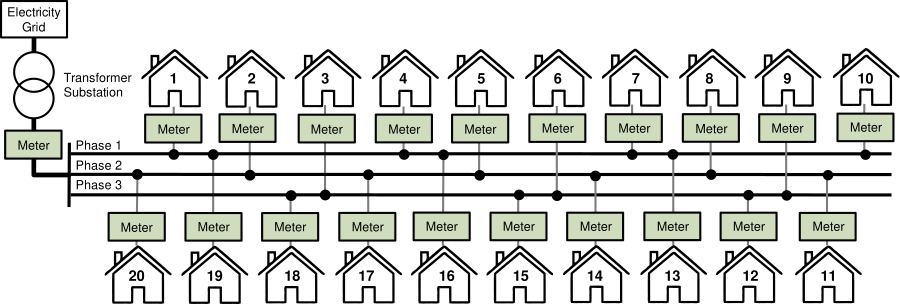








Cada cliente cuenta con un medidor inteligente que registra cuánta energía ha consumido durante un mes. Los valores de consumo son los siguentes:




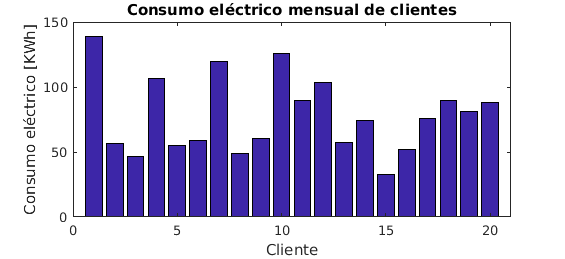




La energía total registrada en la fase "i" del transformador puede ser calculada sumando la energía consumida por todos los clientes conectados a dicha fase. Los consumos por fase son:




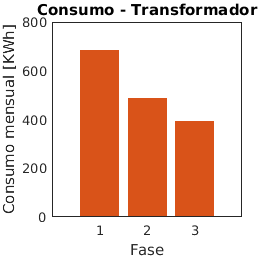




Debido a que existe una gran diferencia de consumo entre las fases, pueden ocurrir pérdidas de energía y se reduce la calidad del servicio eléctrico, entre otros inconvenientes.

Se pide resolver el problema de balance de carga, el cual consiste en equilibrar el valor del consumo eléctrico en cada una de las fases. Para lograrlo se pude cambiar de fase a algunos clientes. Dicho en otras palabras, se pide encontrar un nuevo esquema de conexión, de manera tal que el consumo total en cada fase sea aproximadamente el mismo.

Resuelva las siguientes dos variantes del problema:
1.  Teniendo en cuenta sólo reducir el desbalance de cargas en el transformador.
2.  Teniendo en cuenta reducir el desbalance con la mínima cantidad de cambios de fase.

Se pide:
*   Determine qué codificación utilizará para el problema (cómo representará las soluciones).
*   Diseñe una función de evaluación.
*   Seleccione los operadores genéticos adecuados para el problema.
*   Utilice un AG simple para encontrar una solución al problema.



## Variante 1:

### 1. Codificación
Se utiliza una codificación **entera** ${1, 2, 3}$ de longitud fija $N = 20$
- **Restricciones:**
    - `Bounds = [[1,3]] * 20` $\rightarrow$ cada gen está acotado al intervalo discreto $[1,3]$
    - `Enteras = [True] * 20` $\rightarrow$ todas las variables son enteras

### 2. Función de Evaluación:
La cátedra nos provee `indice_balance`, el cual mide el desvío porcentual de la fase más cargada respecto al promedio ideal. Dado que el objetivo es minimizar el desbalance, definimos la función de fitness como el **opuesto del índice de desbalance**:
$$\text{Fitness}(X) = -\,\text{indice\_desbalance}\big(\text{consumo\_fases}(\text{consumos\_iniciales}, X)\big)$$

### 3. Operadores Genéticos:
- **Operador de Selección - Torneo con Reposición (`sel_torneo_con_rep`, $k=2$):**
    - El torneo binario ($k=2$) trabaja directamente sobre el orden relativo de los valores de fitness (por lo que opera sin inconvenientes con valores negativos) y mantiene una presión selectiva equilibrada que evita la convergencia prematura.

- **Operador de Cruzamiento — Cruzamiento Uniforme (`xov_uniform`) o de 1 Punto (`xov_single_point`):**
    - `xov_uniform` decide gen a gen (con $p = 0.5$) si los descendientes heredan la fase asignada por el Padre 1 o por el Padre 2, recombinando subconjuntos de clientes sin sesgo posicional.
    - `xov_single_point` preserva mejor los bloques de clientes ya balanceados que el cruzamiento uniforme, aunque tambien puede mantener muchos clientes desbalanceados si los parámetros del algoritmo genético no están configurados adecuadamente.

- **Operador de Mutación — Mutación Aleatoria Discreta (`mut_random_fase`):**
    - Selecciona un cliente $i$ al azar y cambia su conexión a una nueva fase aleatoria distinta de la actual dentro de $\{1, 2, 3\}$.
    - *Descartados*: No conviene usar `mut_boundary` (ya que solo asignaría las fases extremas 1 o 3, ignorando la fase 2), ni depender únicamente de mut_swap (intercambiar fases entre dos clientes mantiene fija la cantidad de clientes por fase —en la configuración inicial $[7, 7, 6]$— impidiendo explorar repartos como $[6, 7, 7]$ o $[5, 8, 7]$).

In [233]:
import random
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Datos y funciones base del Ejercicio 2 ---
consumos_iniciales = [
    138.49, 56.85, 46.56, 106.58, 54.62, 58.88, 119.36, 49.01, 60.48, 126.07,
    89.31, 103.11, 57.18, 74.37, 32.46, 52.30, 75.53, 89.57, 81.36, 88.20
]

fases_iniciales = [1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2]

def consumo_fases(consumos_clientes, fases_clientes):
    """ Calcular el consumo total por fase a partir del consumo de clientes.

        Parametros
            - consumos_clientes: lista con valores de consumo para cada cliente.
            - fases_clientes: lista con valor de la fase donde se conecta el cliente (valores 1,2 o 3).
            - Devuelve vector con 3 elementos.
    """
    consumos_fases = [0, 0, 0]
    for i, c in enumerate(consumos_clientes):
        consumos_fases[fases_clientes[i] - 1] += c
    return consumos_fases

def indice_desbalance(consumo_fases):
    """Calcula el indice para medir el desbalance de las fases (más alto, más desbalanceado)"""
    return (max(consumo_fases) / (sum(consumo_fases) / 3) - 1) * 100

# --- 2. Función de Fitness para Variante 1 (Desbalance) ---
def fitness_balance_carga(solucion):
    cf = consumo_fases(consumos_iniciales, solucion)
    desbalance = indice_desbalance(cf)
    return -desbalance

# --- 3. Inicialización y Operadores Genéticos para Codificación Entera ---
def init_pop_entera(cant_individuos, fases_base, Bounds):
    """Parte de la conexión actual y genera variantes con entre 1 y 4 cambios de fase."""
    poblacion = [fases_base.copy()]
    for _ in range(cant_individuos - 1):
        p = [random.randint(int(B[0]), int(B[1])) for B in Bounds]
        poblacion.append(p)
    return poblacion

def sel_torneo_con_rep(F, cant_selectos, tam_torneo=2):
    S = []
    n = len(F)
    for _ in range(cant_selectos):
        competidores = random.sample(range(n), k=tam_torneo)
        ganador = max(competidores, key=lambda idx: F[idx])
        S.append(ganador)
    return S

def xov_uniform(P1, P2):
    C1, C2 = [], []
    for g1, g2 in zip(P1, P2):
        if random.random() < 0.5:
            C1.append(g1)
            C2.append(g2)
        else:
            C1.append(g2)
            C2.append(g1)
    return C1, C2

def xov_single_point(P1, P2):
    cut = random.randint(1, len(P1) - 1)
    C1 = P1[:cut] + P2[cut:]
    C2 = P2[:cut] + P1[cut:]
    return C1, C2

def mut_random_fase(P, Bounds):
    """Cambia la fase de un cliente elegido al azar a otra fase válida distinta."""
    C = P.copy()
    i = random.randint(0, len(P) - 1)
    fases_posibles = [f for f in range(int(Bounds[i][0]), int(Bounds[i][1]) + 1) if f != C[i]]
    C[i] = random.choice(fases_posibles)
    return C

# --- 3. Algoritmo Genético Simple (misma arquitectura del TP4) ---
def geneticoSimple(Pop, cant_generac, Bounds, Enteras, sel, xover, mut,
                   cant_cruzados, cant_mutados, cant_elite, param_sel, f, callback=None):
    sol = []
    solF = None
    cant_soluc = len(Pop)
    Fit = [None] * cant_soluc
    traceBest = []
    traceAvg = []
    bestSols = []

    cb_param = None
    p = [i for i in range(cant_soluc)]

    for k in range(cant_soluc):
        Pop[k] = [xi if not Enteras[i] else int(xi + 0.5) for i, xi in enumerate(Pop[k])]
        Fit[k] = f(Pop[k])
    if callback is not None:
        cb_param = callback(Pop, Fit, Bounds, 0, cant_generac, cb_param)

    p_orden = sorted(range(len(Fit)), key=lambda k: Fit[k], reverse=True)

    for gen in range(cant_generac):
        Elite = [[xi for xi in Pop[p_orden[k]]] for k in range(cant_elite)]
        Elite_Fit = [Fit[p_orden[k]] for k in range(cant_elite)]

        p_sel = sel(Fit, cant_soluc, param_sel)
        random.shuffle(p)
        Pop = [Pop[p_sel[k]] for k in p]
        Fit = [Fit[p_sel[k]] for k in p]

        random.shuffle(p)
        for k in range(0, cant_cruzados - 1, 2):
            C1, C2 = xover(Pop[p[k]], Pop[p[k + 1]])
            Pop[p[k]] = [xi for xi in C1]
            Pop[p[k + 1]] = [xi for xi in C2]
            Fit[p[k]] = None
            Fit[p[k + 1]] = None

        random.shuffle(p)
        for k in range(cant_mutados):
            C = mut(Pop[p[k]], Bounds)
            Pop[p[k]] = [xi for xi in C]
            Fit[p[k]] = None

        random.shuffle(p)
        for k in range(cant_elite):
            Pop[p[k]] = Elite[k]
            Fit[p[k]] = Elite_Fit[k]

        for k in range(cant_soluc):
            if Fit[k] is None:
                Pop[k] = [xi if not Enteras[i] else int(xi + 0.5) for i, xi in enumerate(Pop[k])]
                Fit[k] = f(Pop[k])

        p_orden = sorted(range(len(Fit)), key=lambda k: Fit[k], reverse=True)
        traceBest.append(Fit[p_orden[0]])
        traceAvg.append(sum(Fit) / len(Fit))
        bestSols.append([xi for xi in Pop[p_orden[0]]])

        if callback is not None:
            cb_param = callback(Pop, Fit, Bounds, gen, cant_generac, cb_param)

    solF = Fit[p_orden[0]]
    sol = Pop[p_orden[0]]
    return sol, solF, Pop, Fit, traceBest, traceAvg, bestSols


### Intento 1:

- **N° de individuos:** 20
- **N° de generaciones:** 60
- **N° de individuos élite:** 1
- **Operador de Cruzamiento:** Single Point Crossover
- **Porcentaje Cruzados:** 70%
- **Porcentaje Mutados:** 5%

=== ESTADO INICIAL ===
Fases iniciales:    [1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2]
Consumo por fase:   [681.34, 487.89, 391.06] kWh (Ideal: 520.10 kWh)
Índice desbalance:  31.0026%

=== SOLUCIÓN ENCONTRADA (VARIANTE 1) ===
Fases optimizadas:  [2, 1, 1, 3, 1, 3, 1, 3, 2, 3, 2, 2, 2, 3, 3, 2, 1, 1, 3, 1]
Consumo por fase:   [530.69, 500.87, 528.73] kWh
Índice desbalance:  2.0368% (Fitness: -2.0368)
Cambios de fase realizados: 16 de 20 clientes


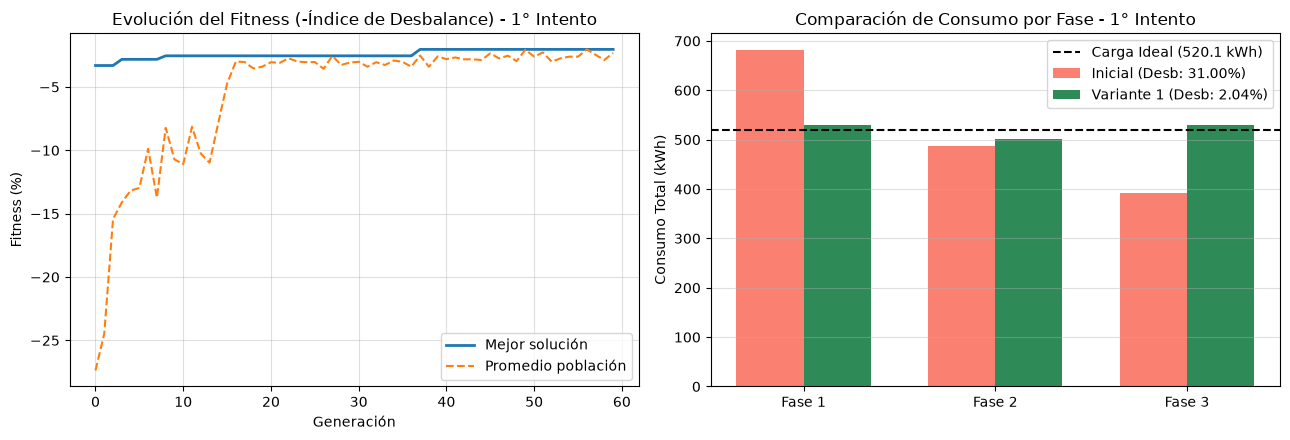

In [279]:
N_clientes = len(consumos_iniciales)
Bounds = [[1, 3]] * N_clientes
Enteras = [True] * N_clientes

cant_individuos = 20
cant_generac    = 60
cant_elite      = 1
sel             = sel_torneo_con_rep
param_sel       = 2
xover           = xov_single_point
cant_cruzados   = round(0.70 * cant_individuos)
mut             = mut_random_fase
cant_mutados    = round(0.05 * cant_individuos)

Pop = init_pop_entera(cant_individuos, fases_iniciales, Bounds)
sol, solF, Pop_fin, Fit_fin, traceBest, traceAvg, _ = geneticoSimple(
    Pop, cant_generac, Bounds, Enteras, sel, xover, mut,
    cant_cruzados, cant_mutados, cant_elite, param_sel, fitness_balance_carga, callback=None
)

# --- 5. Reporte de Resultados y Gráficos ---
cf_inicial = consumo_fases(consumos_iniciales, fases_iniciales)
desb_inicial = indice_desbalance(cf_inicial)

cf_final = consumo_fases(consumos_iniciales, sol)
desb_final = indice_desbalance(cf_final)
cambios_fase = sum(1 for a, b in zip(fases_iniciales, sol) if a != b)
carga_ideal = sum(consumos_iniciales) / 3

print("=== ESTADO INICIAL ===")
print(f"Fases iniciales:    {fases_iniciales}")
print(f"Consumo por fase:   {[round(x, 2) for x in cf_inicial]} kWh (Ideal: {carga_ideal:.2f} kWh)")
print(f"Índice desbalance:  {desb_inicial:.4f}%\n")

print("=== SOLUCIÓN ENCONTRADA (VARIANTE 1) ===")
print(f"Fases optimizadas:  {sol}")
print(f"Consumo por fase:   {[round(x, 2) for x in cf_final]} kWh")
print(f"Índice desbalance:  {desb_final:.4f}% (Fitness: {solF:.4f})")
print(f"Cambios de fase realizados: {cambios_fase} de {N_clientes} clientes")

# Gráficos comparativos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Evolución del Fitness
ax1.plot(traceBest, label='Mejor solución', color='tab:blue', linewidth=2)
ax1.plot(traceAvg, label='Promedio población', color='tab:orange', linestyle='--')
ax1.set_title('Evolución del Fitness (-Índice de Desbalance) - 1° Intento')
ax1.set_xlabel('Generación')
ax1.set_ylabel('Fitness (%)')
ax1.grid(True, alpha=0.4)
ax1.legend()

# Comparación de cargas por fase
fases_labels = ['Fase 1', 'Fase 2', 'Fase 3']
x_pos = np.arange(len(fases_labels))
width = 0.35

ax2.bar(x_pos - width/2, cf_inicial, width, label=f'Inicial (Desb: {desb_inicial:.2f}%)', color='salmon')
ax2.bar(x_pos + width/2, cf_final, width, label=f'Variante 1 (Desb: {desb_final:.2f}%)', color='seagreen')
ax2.axhline(carga_ideal, color='black', linestyle='--', label=f'Carga Ideal ({carga_ideal:.1f} kWh)')
ax2.set_title('Comparación de Consumo por Fase - 1° Intento')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(fases_labels)
ax2.set_ylabel('Consumo Total (kWh)')
ax2.grid(True, axis='y', alpha=0.4)
ax2.legend()

plt.tight_layout()
plt.show()

### Intento 2:

- **N° de individuos:** 20
- **N° de generaciones:** 25
- **N° de individuos élite:** 1
- **Operador de Cruzamiento:** Uniform Crossover
- **Porcentaje Cruzados:** 60%
- **Porcentaje Mutados:** 5%

=== ESTADO INICIAL ===
Fases iniciales:    [1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2]
Consumo por fase:   [681.34, 487.89, 391.06] kWh (Ideal: 520.10 kWh)
Índice desbalance:  31.0026%

=== SOLUCIÓN ENCONTRADA (VARIANTE 1) ===
Fases optimizadas:  [3, 1, 3, 3, 1, 2, 3, 1, 2, 1, 2, 2, 3, 2, 2, 3, 1, 1, 1, 2]
Consumo por fase:   [533.01, 506.81, 520.47] kWh
Índice desbalance:  2.4829% (Fitness: -2.4829)
Cambios de fase realizados: 14 de 20 clientes


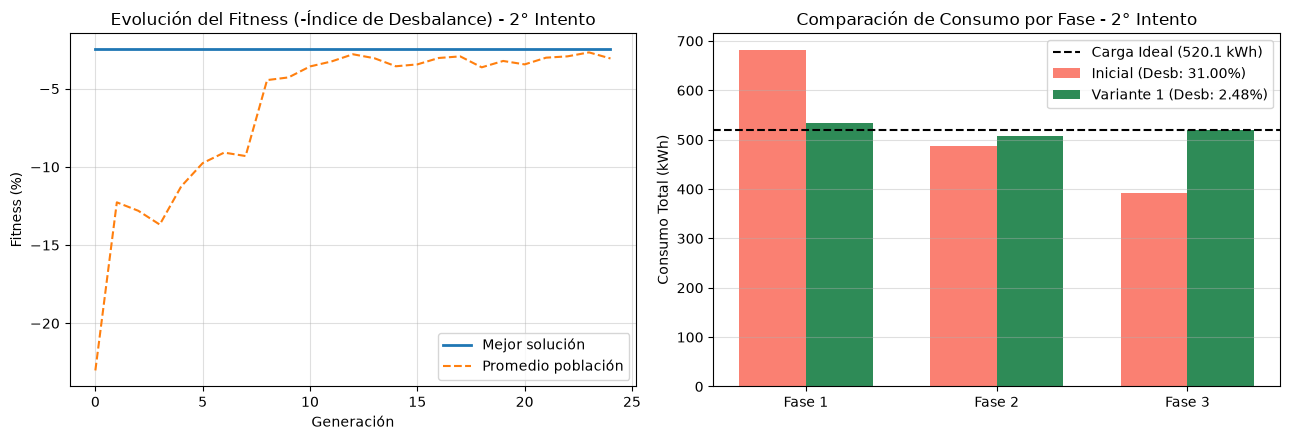

In [281]:
N_clientes = len(consumos_iniciales)
Bounds = [[1, 3]] * N_clientes
Enteras = [True] * N_clientes

cant_individuos = 20
cant_generac    = 25
cant_elite      = 1
sel             = sel_torneo_con_rep
param_sel       = 2
xover           = xov_uniform
cant_cruzados   = round(0.60 * cant_individuos)
mut             = mut_random_fase
cant_mutados    = round(0.05 * cant_individuos)

Pop = init_pop_entera(cant_individuos, fases_iniciales, Bounds)
sol, solF, Pop_fin, Fit_fin, traceBest, traceAvg, _ = geneticoSimple(
    Pop, cant_generac, Bounds, Enteras, sel, xover, mut,
    cant_cruzados, cant_mutados, cant_elite, param_sel, fitness_balance_carga, callback=None
)

# --- 5. Reporte de Resultados y Gráficos ---
cf_inicial = consumo_fases(consumos_iniciales, fases_iniciales)
desb_inicial = indice_desbalance(cf_inicial)

cf_final = consumo_fases(consumos_iniciales, sol)
desb_final = indice_desbalance(cf_final)
cambios_fase = sum(1 for a, b in zip(fases_iniciales, sol) if a != b)
carga_ideal = sum(consumos_iniciales) / 3

print("=== ESTADO INICIAL ===")
print(f"Fases iniciales:    {fases_iniciales}")
print(f"Consumo por fase:   {[round(x, 2) for x in cf_inicial]} kWh (Ideal: {carga_ideal:.2f} kWh)")
print(f"Índice desbalance:  {desb_inicial:.4f}%\n")

print("=== SOLUCIÓN ENCONTRADA (VARIANTE 1) ===")
print(f"Fases optimizadas:  {sol}")
print(f"Consumo por fase:   {[round(x, 2) for x in cf_final]} kWh")
print(f"Índice desbalance:  {desb_final:.4f}% (Fitness: {solF:.4f})")
print(f"Cambios de fase realizados: {cambios_fase} de {N_clientes} clientes")

# Gráficos comparativos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Evolución del Fitness
ax1.plot(traceBest, label='Mejor solución', color='tab:blue', linewidth=2)
ax1.plot(traceAvg, label='Promedio población', color='tab:orange', linestyle='--')
ax1.set_title('Evolución del Fitness (-Índice de Desbalance) - 2° Intento')
ax1.set_xlabel('Generación')
ax1.set_ylabel('Fitness (%)')
ax1.grid(True, alpha=0.4)
ax1.legend()

# Comparación de cargas por fase
fases_labels = ['Fase 1', 'Fase 2', 'Fase 3']
x_pos = np.arange(len(fases_labels))
width = 0.35

ax2.bar(x_pos - width/2, cf_inicial, width, label=f'Inicial (Desb: {desb_inicial:.2f}%)', color='salmon')
ax2.bar(x_pos + width/2, cf_final, width, label=f'Variante 1 (Desb: {desb_final:.2f}%)', color='seagreen')
ax2.axhline(carga_ideal, color='black', linestyle='--', label=f'Carga Ideal ({carga_ideal:.1f} kWh)')
ax2.set_title('Comparación de Consumo por Fase - 2° Intento')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(fases_labels)
ax2.set_ylabel('Consumo Total (kWh)')
ax2.grid(True, axis='y', alpha=0.4)
ax2.legend()

plt.tight_layout()
plt.show()

## Variante 2:

### 1. Codificación
Se utiliza una codificación **entera** ${1, 2, 3}$ de longitud fija $N = 20$ con las mismas restricciones que en la **Variante 1**

### 2. Función de Evaluación:
En esta variante existen dos objetivos en conflicto que deben minimizarse:
1. **Índice de desbalance porcentual ($D$):** Medido mediante indice_desbalance(consumo_fases) (parte de $31.00\%$ y su ideal es $0\%$).
2. **Cantidad de cambios de fase ($C$):** Número de clientes cuya fase asignada difiere de fases_iniciales, con $C \in [0, 20]$.
Para optimizar ambos criterios dentro de geneticoSimple (que maximiza aptitud), se emplea una **suma ponderada negativa:**
$$\text{Fitness}(X) = -\big(w_1 \cdot D(X) + w_2 \cdot C(X)\big)$$
- **Calibración de pesos ($w_1 = 1.0$, $w_2 = 1.0$):**
    - El estado inicial ($D = 31.00\%$, $C = 0$) obtiene $\text{Fitness} = -31.00$.
    - Como $D$ se expresa en puntos porcentuales ($0$ a $31$) y $C$ en unidades enteras ($0$ a $20$), asignar $w_1 = 1.0$ y $w_2 = 1.0$ establece que cada cambio de fase adicional debe justificarse reduciendo al menos $1\%$ de desbalance.

### 3. Operadores Genéticos:
- **Operador de Selección - Torneo con Reposición (`sel_torneo_con_rep`, $k=2$):**

- **Operador de Cruzamiento — Cruzamiento Uniforme (`xov_uniform`)**

- **Operador de Mutación — Mutación Aleatoria Discreta (`mut_random_fase`):**

In [282]:
import random
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Datos y funciones base del Ejercicio 2 ---
consumos_iniciales = [
    138.49, 56.85, 46.56, 106.58, 54.62, 58.88, 119.36, 49.01, 60.48, 126.07,
    89.31, 103.11, 57.18, 74.37, 32.46, 52.30, 75.53, 89.57, 81.36, 88.20
]

fases_iniciales = [1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2]

def consumo_fases(consumos_clientes, fases_clientes):
    consumos_fases = [0, 0, 0]
    for i, c in enumerate(consumos_clientes):
        consumos_fases[fases_clientes[i] - 1] += c
    return consumos_fases

def indice_desbalance(consumo_fases):
    return (max(consumo_fases) / (sum(consumo_fases) / 3) - 1) * 100

def contar_cambios_fase(fases_orig, fases_nuevas):
    return sum(1 for f_ini, f_fin in zip(fases_orig, fases_nuevas) if f_ini != f_fin)

# --- 2. Función de Fitness para Variante 2 (Desbalance + Mínimos Cambios de Fase) ---
def fitness_balance_min_cambios(solucion, w_desb=1.0, w_cambios=1.0):
    cf = consumo_fases(consumos_iniciales, solucion)
    desbalance = indice_desbalance(cf)
    cambios = contar_cambios_fase(fases_iniciales, solucion)
    return -(w_desb * desbalance + w_cambios * cambios)


# --- 3. Inicialización y Operadores Genéticos para Codificación Entera ---
def init_pop_entera(cant_individuos, fases_base, Bounds):
    """Parte de la conexión actual y genera variantes con entre 1 y 4 cambios de fase."""
    poblacion = [fases_base.copy()]
    for _ in range(cant_individuos - 1):
        p = [random.randint(int(B[0]), int(B[1])) for B in Bounds]
        poblacion.append(p)
    return poblacion

### Intento 1:

- **N° de individuos:** 30
- **N° de generaciones:** 60
- **N° de individuos élite:** 1
- **Operador de Cruzamiento:** Uniform Crossover
- **Porcentaje Cruzados:** 70%
- **Porcentaje Mutados:** 3.33%

=== ESTADO INICIAL ===
Fases iniciales:    [1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2]
Consumo por fase:   [681.34, 487.89, 391.06] kWh (Ideal: 520.10 kWh)
Índice desbalance:  31.0026%

=== SOLUCIÓN ENCONTRADA (VARIANTE 2) ===
Fases optimizadas:  [1, 1, 3, 3, 3, 3, 2, 2, 3, 1, 3, 2, 2, 3, 3, 1, 1, 2, 1, 2]
Consumo por fase:   [530.6, 506.43, 523.26] kWh
Índice desbalance:  2.0195%
Cambios de fase:    10 de 20 clientes
Fitness total:      -12.0195

--- Detalle de maniobras de reconexión requeridas ---
  * Cliente 02 (Consumo:  56.85 kWh): Fase 2 -> Fase 1
  * Cliente 04 (Consumo: 106.58 kWh): Fase 1 -> Fase 3
  * Cliente 05 (Consumo:  54.62 kWh): Fase 2 -> Fase 3
  * Cliente 07 (Consumo: 119.36 kWh): Fase 1 -> Fase 2
  * Cliente 11 (Consumo:  89.31 kWh): Fase 2 -> Fase 3
  * Cliente 12 (Consumo: 103.11 kWh): Fase 3 -> Fase 2
  * Cliente 13 (Consumo:  57.18 kWh): Fase 1 -> Fase 2
  * Cliente 14 (Consumo:  74.37 kWh): Fase 2 -> Fase 3
  * Cliente 17 (Consumo:  75.53 kWh):

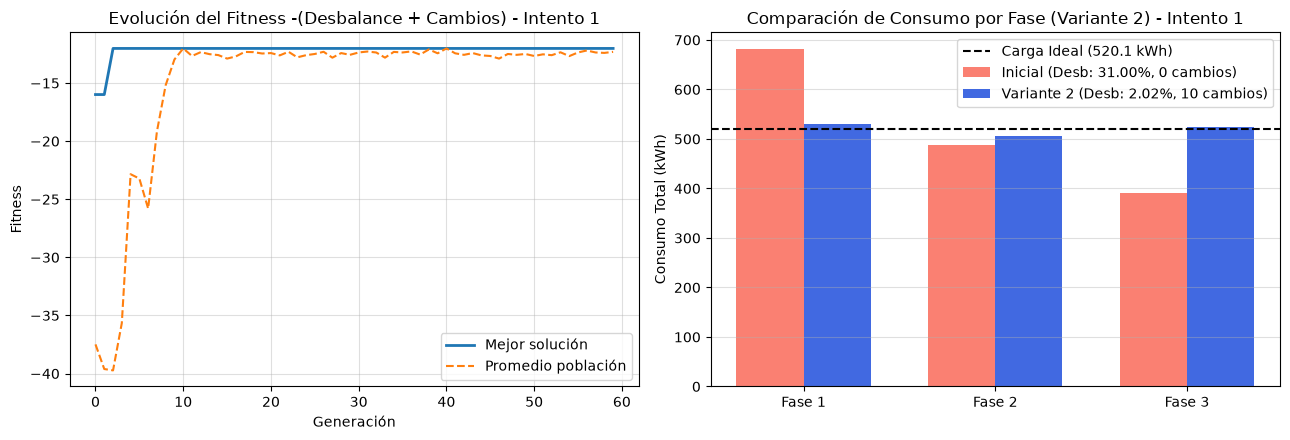

In [283]:
N_clientes = len(consumos_iniciales)
Bounds = [[1, 3]] * N_clientes
Enteras = [True] * N_clientes

cant_individuos = 30
cant_generac    = 60
cant_elite      = 1
sel             = sel_torneo_con_rep
param_sel       = 2
xover           = xov_uniform
mut             = mut_random_fase
cant_cruzados   = round(0.70 * cant_individuos)
cant_mutados    = round(0.033 * cant_individuos)

Pop = init_pop_entera(cant_individuos, fases_iniciales, Bounds)

sol_v2, solF_v2, Pop_fin, Fit_fin, traceBest, traceAvg, _ = geneticoSimple(
    Pop, cant_generac, Bounds, Enteras, sel, xover, mut,
    cant_cruzados, cant_mutados, cant_elite, param_sel,
    fitness_balance_min_cambios,  # <-- Función de aptitud de la Variante 2
    callback=None
)

# --- 5. Reporte de Resultados y Gráficos ---
cf_inicial = consumo_fases(consumos_iniciales, fases_iniciales)
desb_inicial = indice_desbalance(cf_inicial)

cf_v2 = consumo_fases(consumos_iniciales, sol_v2)
desb_v2 = indice_desbalance(cf_v2)
cambios_v2 = contar_cambios_fase(fases_iniciales, sol_v2)
carga_ideal = sum(consumos_iniciales) / 3

print("=== ESTADO INICIAL ===")
print(f"Fases iniciales:    {fases_iniciales}")
print(f"Consumo por fase:   {[round(x, 2) for x in cf_inicial]} kWh (Ideal: {carga_ideal:.2f} kWh)")
print(f"Índice desbalance:  {desb_inicial:.4f}%\n")

print("=== SOLUCIÓN ENCONTRADA (VARIANTE 2) ===")
print(f"Fases optimizadas:  {sol_v2}")
print(f"Consumo por fase:   {[round(x, 2) for x in cf_v2]} kWh")
print(f"Índice desbalance:  {desb_v2:.4f}%")
print(f"Cambios de fase:    {cambios_v2} de {N_clientes} clientes")
print(f"Fitness total:      {solF_v2:.4f}\n")

print("--- Detalle de maniobras de reconexión requeridas ---")
for i in range(N_clientes):
    if fases_iniciales[i] != sol_v2[i]:
        print(f"  * Cliente {i+1:02d} (Consumo: {consumos_iniciales[i]:6.2f} kWh): Fase {fases_iniciales[i]} -> Fase {sol_v2[i]}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(traceBest, label='Mejor solución', color='tab:blue', linewidth=2)
ax1.plot(traceAvg, label='Promedio población', color='tab:orange', linestyle='--')
ax1.set_title('Evolución del Fitness -(Desbalance + Cambios) - Intento 1')
ax1.set_xlabel('Generación')
ax1.set_ylabel('Fitness')
ax1.grid(True, alpha=0.4)
ax1.legend()

fases_labels = ['Fase 1', 'Fase 2', 'Fase 3']
x_pos = np.arange(len(fases_labels))
width = 0.35

ax2.bar(x_pos - width/2, cf_inicial, width, label=f'Inicial (Desb: {desb_inicial:.2f}%, 0 cambios)', color='salmon')
ax2.bar(x_pos + width/2, cf_v2, width, label=f'Variante 2 (Desb: {desb_v2:.2f}%, {cambios_v2} cambios)', color='royalblue')
ax2.axhline(carga_ideal, color='black', linestyle='--', label=f'Carga Ideal ({carga_ideal:.1f} kWh)')
ax2.set_title('Comparación de Consumo por Fase (Variante 2) - Intento 1')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(fases_labels)
ax2.set_ylabel('Consumo Total (kWh)')
ax2.grid(True, axis='y', alpha=0.4)
ax2.legend()

plt.tight_layout()
plt.show()

### Intento 2:

- **N° de individuos:** 60
- **N° de generaciones:** 120
- **N° de individuos élite:** 2
- **Operador de Cruzamiento:** Uniform Crossover
- **Porcentaje Cruzados:** 80%
- **Porcentaje Mutados:** 15%

=== ESTADO INICIAL ===
Fases iniciales:    [1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2]
Consumo por fase:   [681.34, 487.89, 391.06] kWh (Ideal: 520.10 kWh)
Índice desbalance:  31.0026%

=== SOLUCIÓN ENCONTRADA (VARIANTE 2) ===
Fases optimizadas:  [3, 2, 3, 1, 2, 1, 3, 2, 3, 3, 2, 2, 1, 2, 3, 1, 1, 1, 1, 2]
Consumo por fase:   [521.4, 515.47, 523.42] kWh
Índice desbalance:  0.6390%
Cambios de fase:    7 de 20 clientes
Fitness total:      -7.6390

--- Detalle de maniobras de reconexión requeridas ---
  * Cliente 01 (Consumo: 138.49 kWh): Fase 1 -> Fase 3
  * Cliente 06 (Consumo:  58.88 kWh): Fase 3 -> Fase 1
  * Cliente 07 (Consumo: 119.36 kWh): Fase 1 -> Fase 3
  * Cliente 10 (Consumo: 126.07 kWh): Fase 1 -> Fase 3
  * Cliente 12 (Consumo: 103.11 kWh): Fase 3 -> Fase 2
  * Cliente 17 (Consumo:  75.53 kWh): Fase 2 -> Fase 1
  * Cliente 18 (Consumo:  89.57 kWh): Fase 3 -> Fase 1


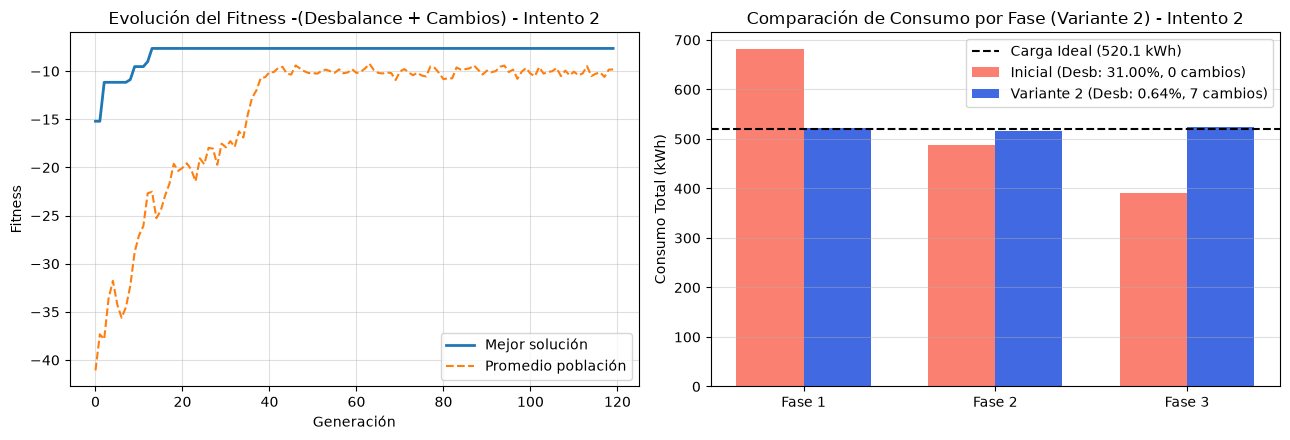

In [287]:
N_clientes = len(consumos_iniciales)
Bounds = [[1, 3]] * N_clientes
Enteras = [True] * N_clientes

cant_individuos = 60
cant_generac    = 120
cant_elite      = 2
sel             = sel_torneo_con_rep
param_sel       = 2
xover           = xov_uniform
mut             = mut_random_fase
cant_cruzados   = round(0.80 * cant_individuos)
cant_mutados    = round(0.15 * cant_individuos)

Pop = init_pop_entera(cant_individuos, fases_iniciales, Bounds)

sol_v2, solF_v2, Pop_fin, Fit_fin, traceBest, traceAvg, _ = geneticoSimple(
    Pop, cant_generac, Bounds, Enteras, sel, xover, mut,
    cant_cruzados, cant_mutados, cant_elite, param_sel,
    fitness_balance_min_cambios,  # <-- Función de aptitud de la Variante 2
    callback=None
)

# --- 5. Reporte de Resultados y Gráficos ---
cf_inicial = consumo_fases(consumos_iniciales, fases_iniciales)
desb_inicial = indice_desbalance(cf_inicial)

cf_v2 = consumo_fases(consumos_iniciales, sol_v2)
desb_v2 = indice_desbalance(cf_v2)
cambios_v2 = contar_cambios_fase(fases_iniciales, sol_v2)
carga_ideal = sum(consumos_iniciales) / 3

print("=== ESTADO INICIAL ===")
print(f"Fases iniciales:    {fases_iniciales}")
print(f"Consumo por fase:   {[round(x, 2) for x in cf_inicial]} kWh (Ideal: {carga_ideal:.2f} kWh)")
print(f"Índice desbalance:  {desb_inicial:.4f}%\n")

print("=== SOLUCIÓN ENCONTRADA (VARIANTE 2) ===")
print(f"Fases optimizadas:  {sol_v2}")
print(f"Consumo por fase:   {[round(x, 2) for x in cf_v2]} kWh")
print(f"Índice desbalance:  {desb_v2:.4f}%")
print(f"Cambios de fase:    {cambios_v2} de {N_clientes} clientes")
print(f"Fitness total:      {solF_v2:.4f}\n")

print("--- Detalle de maniobras de reconexión requeridas ---")
for i in range(N_clientes):
    if fases_iniciales[i] != sol_v2[i]:
        print(f"  * Cliente {i+1:02d} (Consumo: {consumos_iniciales[i]:6.2f} kWh): Fase {fases_iniciales[i]} -> Fase {sol_v2[i]}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(traceBest, label='Mejor solución', color='tab:blue', linewidth=2)
ax1.plot(traceAvg, label='Promedio población', color='tab:orange', linestyle='--')
ax1.set_title('Evolución del Fitness -(Desbalance + Cambios) - Intento 2')
ax1.set_xlabel('Generación')
ax1.set_ylabel('Fitness')
ax1.grid(True, alpha=0.4)
ax1.legend()

fases_labels = ['Fase 1', 'Fase 2', 'Fase 3']
x_pos = np.arange(len(fases_labels))
width = 0.35

ax2.bar(x_pos - width/2, cf_inicial, width, label=f'Inicial (Desb: {desb_inicial:.2f}%, 0 cambios)', color='salmon')
ax2.bar(x_pos + width/2, cf_v2, width, label=f'Variante 2 (Desb: {desb_v2:.2f}%, {cambios_v2} cambios)', color='royalblue')
ax2.axhline(carga_ideal, color='black', linestyle='--', label=f'Carga Ideal ({carga_ideal:.1f} kWh)')
ax2.set_title('Comparación de Consumo por Fase (Variante 2) - Intento 2')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(fases_labels)
ax2.set_ylabel('Consumo Total (kWh)')
ax2.grid(True, axis='y', alpha=0.4)
ax2.legend()

plt.tight_layout()
plt.show()

### Intento 3:

- **N° de individuos:** 60
- **N° de generaciones:** 25
- **N° de individuos élite:** 2
- **Operador de Cruzamiento:** Uniform Crossover
- **Porcentaje Cruzados:** 60%
- **Porcentaje Mutados:** 5%

=== ESTADO INICIAL ===
Fases iniciales:    [1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2, 3, 1, 2]
Consumo por fase:   [681.34, 487.89, 391.06] kWh (Ideal: 520.10 kWh)
Índice desbalance:  31.0026%

=== SOLUCIÓN ENCONTRADA (VARIANTE 2) ===
Fases optimizadas:  [2, 1, 3, 1, 2, 3, 3, 2, 3, 3, 2, 1, 1, 1, 3, 1, 2, 3, 1, 2]
Consumo por fase:   [531.75, 495.16, 533.38] kWh
Índice desbalance:  2.5540%
Cambios de fase:    6 de 20 clientes
Fitness total:      -8.5540

--- Detalle de maniobras de reconexión requeridas ---
  * Cliente 01 (Consumo: 138.49 kWh): Fase 1 -> Fase 2
  * Cliente 02 (Consumo:  56.85 kWh): Fase 2 -> Fase 1
  * Cliente 07 (Consumo: 119.36 kWh): Fase 1 -> Fase 3
  * Cliente 10 (Consumo: 126.07 kWh): Fase 1 -> Fase 3
  * Cliente 12 (Consumo: 103.11 kWh): Fase 3 -> Fase 1
  * Cliente 14 (Consumo:  74.37 kWh): Fase 2 -> Fase 1


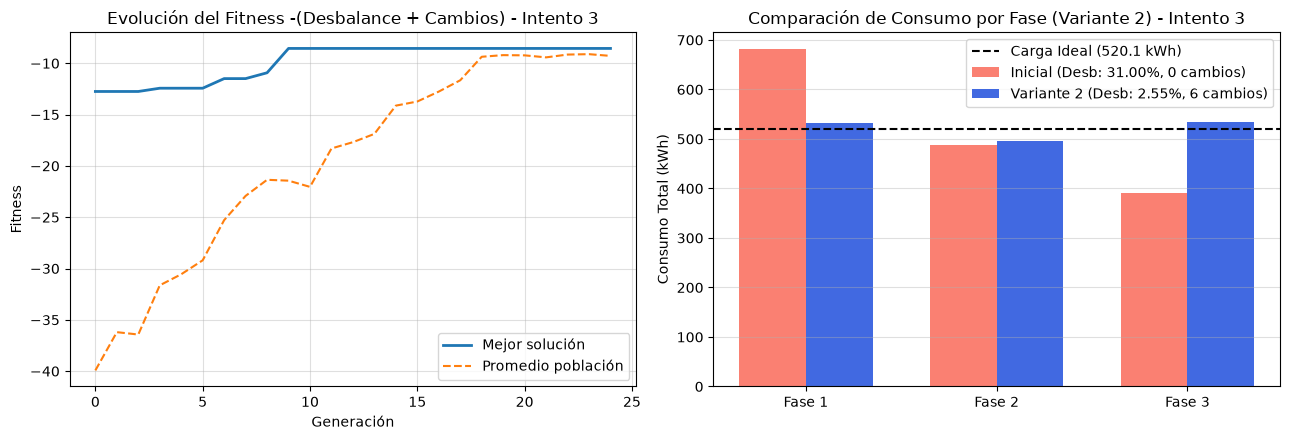

In [298]:
N_clientes = len(consumos_iniciales)
Bounds = [[1, 3]] * N_clientes
Enteras = [True] * N_clientes

cant_individuos = 60
cant_generac    = 25
cant_elite      = 2
sel             = sel_torneo_con_rep
param_sel       = 2
xover           = xov_uniform
mut             = mut_random_fase
cant_cruzados   = round(0.60 * cant_individuos)
cant_mutados    = round(0.05 * cant_individuos)

Pop = init_pop_entera(cant_individuos, fases_iniciales, Bounds)

sol_v2, solF_v2, Pop_fin, Fit_fin, traceBest, traceAvg, _ = geneticoSimple(
    Pop, cant_generac, Bounds, Enteras, sel, xover, mut,
    cant_cruzados, cant_mutados, cant_elite, param_sel,
    fitness_balance_min_cambios,  # <-- Función de aptitud de la Variante 2
    callback=None
)

# --- 5. Reporte de Resultados y Gráficos ---
cf_inicial = consumo_fases(consumos_iniciales, fases_iniciales)
desb_inicial = indice_desbalance(cf_inicial)

cf_v2 = consumo_fases(consumos_iniciales, sol_v2)
desb_v2 = indice_desbalance(cf_v2)
cambios_v2 = contar_cambios_fase(fases_iniciales, sol_v2)
carga_ideal = sum(consumos_iniciales) / 3

print("=== ESTADO INICIAL ===")
print(f"Fases iniciales:    {fases_iniciales}")
print(f"Consumo por fase:   {[round(x, 2) for x in cf_inicial]} kWh (Ideal: {carga_ideal:.2f} kWh)")
print(f"Índice desbalance:  {desb_inicial:.4f}%\n")

print("=== SOLUCIÓN ENCONTRADA (VARIANTE 2) ===")
print(f"Fases optimizadas:  {sol_v2}")
print(f"Consumo por fase:   {[round(x, 2) for x in cf_v2]} kWh")
print(f"Índice desbalance:  {desb_v2:.4f}%")
print(f"Cambios de fase:    {cambios_v2} de {N_clientes} clientes")
print(f"Fitness total:      {solF_v2:.4f}\n")

print("--- Detalle de maniobras de reconexión requeridas ---")
for i in range(N_clientes):
    if fases_iniciales[i] != sol_v2[i]:
        print(f"  * Cliente {i+1:02d} (Consumo: {consumos_iniciales[i]:6.2f} kWh): Fase {fases_iniciales[i]} -> Fase {sol_v2[i]}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(traceBest, label='Mejor solución', color='tab:blue', linewidth=2)
ax1.plot(traceAvg, label='Promedio población', color='tab:orange', linestyle='--')
ax1.set_title('Evolución del Fitness -(Desbalance + Cambios) - Intento 3')
ax1.set_xlabel('Generación')
ax1.set_ylabel('Fitness')
ax1.grid(True, alpha=0.4)
ax1.legend()

fases_labels = ['Fase 1', 'Fase 2', 'Fase 3']
x_pos = np.arange(len(fases_labels))
width = 0.35

ax2.bar(x_pos - width/2, cf_inicial, width, label=f'Inicial (Desb: {desb_inicial:.2f}%, 0 cambios)', color='salmon')
ax2.bar(x_pos + width/2, cf_v2, width, label=f'Variante 2 (Desb: {desb_v2:.2f}%, {cambios_v2} cambios)', color='royalblue')
ax2.axhline(carga_ideal, color='black', linestyle='--', label=f'Carga Ideal ({carga_ideal:.1f} kWh)')
ax2.set_title('Comparación de Consumo por Fase (Variante 2) - Intento 3')
ax2.set_xticks(x_pos)
ax2.set_xticklabels(fases_labels)
ax2.set_ylabel('Consumo Total (kWh)')
ax2.grid(True, axis='y', alpha=0.4)
ax2.legend()

plt.tight_layout()
plt.show()

### Conclusiones sobre el Ejercicio 2

1. **Selección por Torneo Binario (sel_torneo_con_rep, $k=2$) y Elitismo ($1$–$2$ individuos):**
    - La presión selectiva del torneo binario impulsa un crecimiento acelerado del **Promedio población** durante las primeras $10$ a $15$ generaciones en todas las ejecuciones, eliminando rápidamente las asignaciones de fase más desbalanceadas.
    - El elitismo garantiza que **Mejor solución** nunca decaiga, manteniendo intactos los mejores esquemas mientras el resto de la población explora nuevas combinaciones.
2. **Influencia del Operador y Tasa de Cruzamiento (Single Point vs. Uniform):**
    - *Cruzamiento Uniforme (`xov_uniform`, $60\%$–$80\%$):* Al recombinar cada cliente de forma independiente sin sesgo posicional, acelera la convergencia inicial de Promedio población (alcanzando la meseta superior entre las generaciones $8$ y $10$ en el Intento 2 de la Variante 1 y el Intento 1 de la Variante 2).
    - Cruzamiento de Un Punto (`xov_single_point`, $70\%$): Al intercambiar bloques contiguos de clientes, genera una evolución más gradual y escalonada de Mejor solución, la cual puede ser útil cuando se le plantean numerosos individuos y generaciones al algoritmo para alcanzar el óptimo global; sin embargo, como en el problema sólamente existen 3 fases, las combinaciones posibles son pocas cuando se trabajan con pequeña población y pocas generaciones, lo cual obstaculiza al algoritmo genético alcanzar o acercarse al óptimo global.
3. **Influencia de la Mutación (`mut_random_fase`) y Tamaño de Población en el Crowding**:
    - Tamaño de la población: Al trabajar con una población grande (por ejemplo, 100 individuos), se alcanza rápidamente el Crowding en las primeras generaciones debido a la escasa cantidad de fases en el problema; con menor cantidad de individuos (20) la diversidad genética de los descendientes será menor, lo cual permitirá una evolución más leve en **Promedio población**
    - Mutación: Al trabajar con poblaciones pequeñas, si incluimos un nivel moderado/alto de mutación (por ejemplo, 15%), el **Promedio población** presentará numerosos altibajos, e incluso puede provocar que este no confluya con **Mejor solución**; con un nivel bajo (5%), este comportamiento se mitigará, y el algoritmo podrá lograr la similitud en el valor final de ambas curvas